# Readout twirling (TREX-style)

**Question:** Can randomizing measurements and rescaling the pair correlations improve the estimated mean cost?

TREX is a readout-mitigation method for expectation values. This notebook uses random X flips before measurement, undoes those flips in software, and estimates a calibration scale for each SNP bit. It compares that estimate with the current local-matrix correction and raw sampling. It does not produce corrected bitstrings or an optimum frequency.

## 1. Load the fixed problem

The [shared setup](hardware_setup.ipynb) supplies the same reads, angles and cost as the other experiments.

In [1]:
from pathlib import Path
setup_path = Path('hardware_setup.ipynb')
if not setup_path.exists():
    setup_path = Path('hardware/hardware_setup.ipynb')
if not setup_path.exists():
    setup_path = Path('experiments/hardware/hardware_setup.ipynb')
%run $setup_path

5 SNPs, 9 active interactions, backend: fake_manila
Exact minimum: 1
The reversed SNP order keeps the same ideal output distribution.


## 2. Compile one circuit and keep its measurement map

All arms use this compiled circuit. I add X gates only immediately before measurement; after sampling, I undo each known flip on its matching classical bit.

In [2]:
manager = generate_preset_pass_manager(
    backend=backend, optimization_level=2, seed_transpiler=71,
)
compiled = manager.run(make_circuit())
measurement_map = {
    compiled.find_bit(item.clbits[0]).index: compiled.find_bit(item.qubits[0]).index
    for item in compiled.data if item.operation.name == 'measure'
}
assert set(measurement_map) == set(range(n))
print('Classical SNP bit to physical qubit:', measurement_map)
print('Compiled resources:', resources(compiled))

Classical SNP bit to physical qubit: {0: 0, 1: 4, 2: 3, 3: 1, 4: 2}
Compiled resources: {'2q gates': 29, '2q depth': 24, 'depth': 49}


## 3. Get the simulated value before readout errors

For this small simulator test, I remove measurement and calculate the exact noisy mean cost. It is a reference for how much readout correction helps; real hardware would not provide this value. Density-matrix memory grows quickly, so the calculation is skipped above ten backend qubits.

In [3]:
reference_cost = None
if backend.num_qubits <= 10:
    before_readout = compiled.remove_final_measurements(inplace=False)
    before_readout.save_probabilities_dict()
    reference_sim = AerSimulator.from_backend(
        backend, method='density_matrix', max_parallel_threads=1,
    )
    probabilities = reference_sim.run(before_readout).result().data(0)['probabilities']
    reference_cost = sum(
        probability * cost([(state >> measurement_map[bit]) & 1 for bit in range(n)])
        for state, probability in probabilities.items()
    )
    print(f'Exact simulated pre-readout mean cost: {reference_cost:.4f}')
else:
    print('Skipped exact reference: density-matrix simulation grows quickly.')

Exact simulated pre-readout mean cost: 8.8542


## 3. Make randomized calibration circuits

Each calibration circuit prepares a different bit pattern using X gates. After measurement, I know which bits were prepared, so I can estimate each bit’s readout response. Random flips before target measurements turn asymmetric readout errors into a simpler scale factor for each pair correlation.

In [4]:
shots_per_arm = 2048
mask_count = min(16, 2 ** n)
if shots_per_arm % mask_count:
    raise ValueError('Choose a mask count that divides shots_per_arm.')
calibration_shots = shots_per_arm // mask_count
mask_rng = np.random.default_rng(91)
masks = []
while len(masks) < mask_count:
    mask = tuple(int(bit) for bit in mask_rng.integers(0, 2, size=n))
    inverse = tuple(1 - bit for bit in mask)
    if mask not in masks and inverse not in masks:
        masks.extend([mask, inverse])

calibration_circuits = []
for mask in masks:
    circuit = QuantumCircuit(backend.num_qubits, n)
    for bit, prepared in enumerate(mask):
        if prepared:
            circuit.x(measurement_map[bit])
        circuit.measure(measurement_map[bit], bit)
    calibration_circuits.append(circuit)
print(f'{mask_count} calibration patterns x {calibration_shots} shots = {shots_per_arm} shots.')

16 calibration patterns x 128 shots = 2048 shots.


Each mask gives an equivalent ideal measurement after its known flips are undone. The masks are paired with their bitwise complements, so each SNP is flipped equally often. I assume readout errors are independent between qubits; this small local test does not model readout crosstalk.

In [5]:
def twirl_measurements(circuit, mask):
    twirled = QuantumCircuit(circuit.num_qubits, circuit.num_clbits)
    twirled.global_phase = circuit.global_phase
    for item in circuit.data:
        qubits = [circuit.find_bit(q).index for q in item.qubits]
        clbits = [circuit.find_bit(c).index for c in item.clbits]
        if item.operation.name == 'measure':
            bit = clbits[0]
            if mask[bit]:
                twirled.x(qubits[0])
            twirled.measure(qubits[0], bit)
        else:
            twirled.append(item.operation, qubits, clbits)
    return twirled

twirled_circuits = [twirl_measurements(compiled, mask) for mask in masks]
if ideal is not None:
    for mask, circuit in zip(masks, twirled_circuits):
        measured = logical_probabilities(circuit)
        mask_value = sum(bit << index for index, bit in enumerate(mask))
        untwirled = np.array([measured[state ^ mask_value] for state in range(2 ** n)])
        assert np.allclose(untwirled, ideal)
    print('After undoing the X masks, all randomized circuits keep the ideal distribution.')

After undoing the X masks, all randomized circuits keep the ideal distribution.


## 5. Estimate the readout response and TREX scales

The local response matrices estimate `P(observed | prepared)` separately for each bit. Their inverse gives the local correction used in the previous readout test. For TREX, the scale is the average correlation between each prepared and observed Z value after randomization.

In [6]:
def response_from_calibration(calibration_counts):
    response = np.zeros((n, 2, 2))
    for mask, counts in zip(masks, calibration_counts):
        for key, count in counts.items():
            observed = [int(bit) for bit in key.replace(' ', '')[::-1]]
            for bit in range(n):
                response[bit, observed[bit], mask[bit]] += count
    for bit in range(n):
        for prepared in (0, 1):
            total = response[bit, :, prepared].sum()
            response[bit, :, prepared] /= total
    if max(np.linalg.cond(matrix) for matrix in response) > 1e6:
        raise ValueError('Calibration is too unstable to invert.')
    return response

def trex_scales(response):
    return np.array([matrix[0, 0] + matrix[1, 1] - 1 for matrix in response])


def local_corrected_mean(counts, response):
    z = np.array([1., -1.]) @ np.linalg.inv(response)
    total = sum(counts.values())
    estimate = 0.
    for key, count in counts.items():
        bits = [int(bit) for bit in key.replace(' ', '')[::-1]]
        for i, j in itertools.combinations(range(n), 2):
            offset = (agree[i, j] + disagree[i, j]) / 2
            weight = (disagree[i, j] - agree[i, j]) / 2
            estimate += count * (offset + weight * z[i, bits[i]] * z[j, bits[j]])
    return estimate / total


def trex_corrected_mean(mask_counts, response):
    scales = trex_scales(response)
    if np.min(np.abs(scales)) < 0.1:
        raise ValueError('Readout is too noisy for a stable TREX rescaling.')
    pair_sums = {(i, j): 0 for i, j in itertools.combinations(range(n), 2)}
    total = 0
    for mask, counts in zip(masks, mask_counts):
        for key, count in counts.items():
            observed = [int(bit) for bit in key.replace(' ', '')[::-1]]
            bits = [observed[bit] ^ mask[bit] for bit in range(n)]
            z_values = [1 - 2 * bit for bit in bits]
            for i, j in pair_sums:
                pair_sums[i, j] += count * z_values[i] * z_values[j]
            total += count
    estimate = 0.
    for (i, j), pair_sum in pair_sums.items():
        offset = (agree[i, j] + disagree[i, j]) / 2
        weight = (disagree[i, j] - agree[i, j]) / 2
        correlation = pair_sum / total / (scales[i] * scales[j])
        estimate += offset + weight * correlation
    return estimate

## 6. Compare at the same shot budget

Each corrected arm uses 2,048 calibration shots and 2,048 target shots. Raw equal-budget uses 4,096 target shots. The ordinary raw result uses 2,048 target shots. I repeat the comparison to show sampling variation.

In [7]:
repeats = 5
simulator = AerSimulator.from_backend(backend, max_parallel_threads=1)
rows = []
for repeat in range(repeats):
    calibration = simulator.run(
        calibration_circuits, shots=calibration_shots,
        seed_simulator=1000 + repeat,
    ).result()
    response = response_from_calibration(
        [calibration.get_counts(index) for index in range(mask_count)]
    )
    raw = simulator.run(
        compiled, shots=shots_per_arm, seed_simulator=2000 + repeat,
    ).result().get_counts()
    twirled = simulator.run(
        twirled_circuits, shots=calibration_shots,
        seed_simulator=3000 + repeat,
    ).result()
    twirled_counts = [twirled.get_counts(index) for index in range(mask_count)]
    raw_equal = simulator.run(
        compiled, shots=2 * shots_per_arm, seed_simulator=4000 + repeat,
    ).result().get_counts()
    rows.extend([
        {'repeat': repeat, 'method': 'raw', 'mean cost': score(raw)['mean cost']},
        {'repeat': repeat, 'method': 'local corrected',
         'mean cost': local_corrected_mean(raw, response)},
        {'repeat': repeat, 'method': 'TREX-style',
         'mean cost': trex_corrected_mean(twirled_counts, response)},
        {'repeat': repeat, 'method': 'raw equal budget',
         'mean cost': score(raw_equal)['mean cost']},
    ])
results = pd.DataFrame(rows)
display(results.pivot(index='repeat', columns='method', values='mean cost').round(3))
display(results.groupby('method')['mean cost'].agg(['mean', 'std']).round(3))
print('Corrected arms: 4,096 shots each, including calibration.')
print('Raw equal-budget arm: 4,096 target shots.')

method,TREX-style,local corrected,raw,raw equal budget
repeat,,,,
0,8.925,8.512,9.071,9.402
1,8.885,8.920,9.406,9.329
2,9.111,8.993,9.463,9.457
3,8.755,8.805,9.292,9.427
4,8.768,8.842,9.358,9.477


,mean,std
method,,
TREX-style,8.889,0.144
local corrected,8.815,0.184
raw,9.318,0.152
raw equal budget,9.419,0.058


Corrected arms: 4,096 shots each, including calibration.
Raw equal-budget arm: 4,096 target shots.


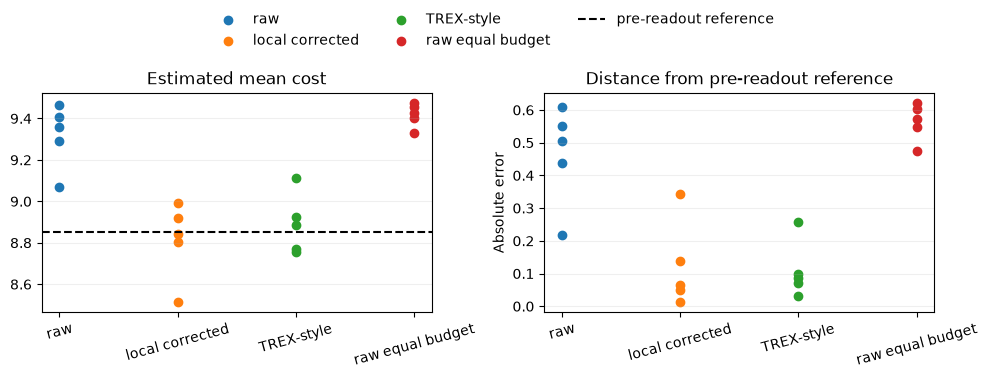

In [8]:
methods = ['raw', 'local corrected', 'TREX-style', 'raw equal budget']
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for index, method in enumerate(methods):
    values = results.loc[results.method == method, 'mean cost']
    axes[0].scatter([index] * len(values), values, label=method)
    if reference_cost is not None:
        axes[1].scatter([index] * len(values), abs(values - reference_cost))
if reference_cost is not None:
    axes[0].axhline(reference_cost, color='black', linestyle='--', label='pre-readout reference')
else:
    axes[1].text(.5, .5, 'Reference skipped', ha='center', transform=axes[1].transAxes)
axes[0].set_title('Estimated mean cost')
axes[1].set_title('Distance from pre-readout reference')
axes[1].set_ylabel('Absolute error')
for ax in axes:
    ax.set_xticks(range(len(methods)), methods, rotation=15)
    ax.grid(axis='y', alpha=.2)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0, 1, .86))
plt.show()

## What did I find?

The exact pre-readout reference is **8.854**. TREX-style and local correction estimated **8.889 ± 0.144** and **8.815 ± 0.184**, while raw sampling was **9.318 ± 0.152**; values are mean ± standard deviation across five repeats, and lower cost is better. Both corrections moved the estimate close to the reference, with no clear advantage for TREX over local correction in this run. This local TREX-style test assumes independent readout errors and estimates mean cost only; it does not return corrected bitstrings or optimum frequency. A second backend is deferred.

## References

- [Model-free readout-error mitigation for quantum expectation values](https://doi.org/10.1103/PhysRevA.105.032620)
- [IBM Quantum guide to error mitigation and suppression](https://quantum.cloud.ibm.com/docs/en/guides/error-mitigation-and-suppression-techniques)